# Deep Learning model for smoothing of PSD noisy curve, estimation of peaks and their frequency ranges.

__COLAB notebook.__ _(everything in it so it can run on colab)_

----------------------------------------------------------------------------------

__Goal:__ return clean PSD, peak and peak frequency interval from noisy PSD.

__Model:__ Unet based Neural Network

----------------------------------------------------------------------------------

The notebook focuses on:
- How to preprocess input data before entering model.
- Which losses to select
- Inference on real data and simulated data


In [ ]:
import os
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import deform_conv2d

import scipy.signal as signal
#%matplotlib tk
import matplotlib.pyplot as plt

In [ ]:
# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

## Classes and Functions

### Helpers

In [ ]:
def to_numpy(tensor):
    return tensor.detach().cpu().numpy().squeeze()

### Dataset Conversion

In [ ]:
def convert_masks_to_target_structures(masks_array, sigma=2.0):
    """
    Converts 2D mask array [N, 2, n_freqs] into targets for Keypoint U-Net:
      - Channel 0: Center binary mask -> 1D Gaussian Heatmap Target [N, 1, n_freqs]
      - Channel 1: Interval binary mask -> Dense Width Targets [N, 2, n_freqs]
    """
    N, _, n_freqs = masks_array.shape
    x_axis = np.arange(n_freqs)

    target_heatmaps = np.zeros((N, 1, n_freqs), dtype=np.float32)
    target_widths   = np.zeros((N, 2, n_freqs), dtype=np.float32)  # [Left_Width, Right_Width]
    peak_masks      = np.zeros((N, 1, n_freqs), dtype=np.float32)  # Active across full peak regions

    for i in range(N):
        center_mask   = masks_array[i, 0]   # Channel 0
        interval_mask = masks_array[i, 1]   # Channel 1

        # Locate peak center indices (where center_mask > 0.5)
        peak_indices = np.where(center_mask > 0.5)[0]

        # 1. Generate 1D Gaussian Heatmap for Peak Head
        for p_idx in peak_indices:
            gaussian = np.exp(-((x_axis - p_idx) ** 2) / (2 * (sigma ** 2)))
            target_heatmaps[i, 0] = np.maximum(target_heatmaps[i, 0], gaussian)

        # 2. Extract Left/Right Interval Widths (DENSE REGRESSION MAPS)
        for p_idx in peak_indices:
            # Step left to measure interval start
            left_bound = p_idx
            while left_bound > 0 and interval_mask[left_bound - 1] > 0.5:
                left_bound -= 1

            # Step right to measure interval end
            right_bound = p_idx
            while right_bound < n_freqs - 1 and interval_mask[right_bound + 1] > 0.5:
                right_bound += 1

            # Populate DENSE offset maps for ALL bins within interval
            for x in range(left_bound, right_bound + 1):
                target_widths[i, 0, x] = float(x - left_bound)   # Distance to left boundary
                target_widths[i, 1, x] = float(right_bound - x)  # Distance to right boundary
                peak_masks[i, 0, x]    = 1.0                    # Mask active across entire peak

    return (
        torch.tensor(target_heatmaps, dtype=torch.float32),
        torch.tensor(target_widths, dtype=torch.float32),
        torch.tensor(peak_masks, dtype=torch.float32)
    )

class ConvertedKeypointPSDDataset(Dataset):
    """
    Dataset class that loads your existing NPZ file format:
    log_noisy_{split}, log_clean_{split}, masks_{split}
    """
    def __init__(self, filepath="psd_dataset_masks.npz", split="train", sigma=2.0):
        assert split in ["train", "val", "test"]
        print(f"Loading split '{split}' from {filepath}...")

        data = np.load(filepath, allow_pickle=True)
        self.f = data["f"]

        log_noisy_data = data[f"log_noisy_{split}"]
        log_clean_data = data[f"log_clean_{split}"]
        masks_data     = data[f"masks_{split}"]       # Shape: [N, 2, n_freqs]

        self.log_noisy = torch.tensor(log_noisy_data, dtype=torch.float32)
        self.log_clean = torch.tensor(log_clean_data, dtype=torch.float32)

        # Enforce 3D shapes [N, 1, n_freqs]
        if self.log_noisy.ndim == 2:
            self.log_noisy = self.log_noisy.unsqueeze(1)
        if self.log_clean.ndim == 2:
            self.log_clean = self.log_clean.unsqueeze(1)

        # Convert 2D masks into continuous Keypoint Targets
        self.target_heatmap, self.target_width, self.peak_mask = convert_masks_to_target_structures(
            masks_data, sigma=sigma
        )
        print(f" -> Successfully loaded & converted {len(self.log_noisy)} samples.")

    def __len__(self):
        return len(self.log_noisy)

    def __getitem__(self, idx):
        return {
            "noisy_psd":      self.log_noisy[idx],      # Input: [1, n_freqs]
            "clean_psd":      self.log_clean[idx],      # Head 1 Target: [1, n_freqs]
            "target_heatmap": self.target_heatmap[idx], # Head 2 Target: [1, n_freqs]
            "target_width":   self.target_width[idx],   # Head 3 Target: [2, n_freqs]
            "peak_mask":      self.peak_mask[idx]       # Mask for Loss: [1, n_freqs]
        }

### Model architecture

Model with some convolution layers replaced by residual convolution.

In [ ]:
# =====================================================================
# SHARED CONV / BOTTLENECK BLOCKS
# =====================================================================
class SqueezeExcitation1D(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        mid_c = max(channels // reduction, 4)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Conv1d(channels, mid_c, kernel_size=1),
            nn.GELU(),
            nn.Conv1d(mid_c, channels, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(x)


class ResConvBlock1D(nn.Module):
    def __init__(self, in_c, out_c, kernel_size=3, padding=1, dilation=1, drop_prob=0.1, use_se=True):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_c, out_c, kernel_size=kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_c),
            nn.GELU(),
            nn.Dropout1d(p=drop_prob),
            nn.Conv1d(out_c, out_c, kernel_size=kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_c),
        )
        self.se = SqueezeExcitation1D(out_c) if use_se else nn.Identity()
        self.shortcut = nn.Conv1d(in_c, out_c, kernel_size=1) if in_c != out_c else nn.Identity()
        self.act = nn.GELU()

    def forward(self, x):
        out = self.se(self.block(x))
        return self.act(out + self.shortcut(x))


class ASPP1D(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        branch_c = out_c // 4
        self.b0 = nn.Sequential(nn.Conv1d(in_c, branch_c, kernel_size=1), nn.BatchNorm1d(branch_c), nn.GELU())
        self.b1 = nn.Sequential(nn.Conv1d(in_c, branch_c, kernel_size=3, padding=2, dilation=2), nn.BatchNorm1d(branch_c), nn.GELU())
        self.b2 = nn.Sequential(nn.Conv1d(in_c, branch_c, kernel_size=3, padding=4, dilation=4), nn.BatchNorm1d(branch_c), nn.GELU())
        self.b3 = nn.Sequential(nn.Conv1d(in_c, branch_c, kernel_size=3, padding=8, dilation=8), nn.BatchNorm1d(branch_c), nn.GELU())
        self.project = nn.Sequential(nn.Conv1d(branch_c * 4, out_c, kernel_size=1), nn.BatchNorm1d(out_c), nn.GELU())

    def forward(self, x):
        feat = torch.cat([self.b0(x), self.b1(x), self.b2(x), self.b3(x)], dim=1)
        return self.project(feat)


# =====================================================================
# 1. ORIGINAL MODEL: ResMultiTaskUNet1D
# =====================================================================
class ResMultiTaskUNet1D(nn.Module):
    def __init__(self, in_channels=1, base_filters=32):
        super().__init__()
        self.enc1 = ResConvBlock1D(in_channels, base_filters, use_se=True)
        self.pool1 = nn.MaxPool1d(2)
        self.enc2 = ResConvBlock1D(base_filters, base_filters * 2, use_se=True)
        self.pool2 = nn.MaxPool1d(2)
        self.enc3 = ResConvBlock1D(base_filters * 2, base_filters * 4, use_se=True)
        self.aspp = ASPP1D(base_filters * 4, base_filters * 4)

        self.up2 = nn.ConvTranspose1d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = ResConvBlock1D(base_filters * 4, base_filters * 2, use_se=True)
        self.up1 = nn.ConvTranspose1d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = ResConvBlock1D(base_filters * 2, base_filters, use_se=True)

        head_mid_c = base_filters // 2
        self.denoise_feat = nn.Sequential(
            nn.Conv1d(base_filters, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.denoise_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.heatmap_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.heatmap_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.width_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c + 1, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.width_out = nn.Sequential(nn.Conv1d(head_mid_c, 2, kernel_size=1), nn.Softplus())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e3 = self.aspp(e3)

        d2 = self.up2(e3)
        if d2.shape[-1] != e2.shape[-1]:
            d2 = F.interpolate(d2, size=e2.shape[-1], mode="linear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        if d1.shape[-1] != e1.shape[-1]:
            d1 = F.interpolate(d1, size=e1.shape[-1], mode="linear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        f_denoise = self.denoise_feat(d1)
        noise_residual = self.denoise_out(f_denoise)
        clean_psd = x - noise_residual

        f_heat = self.heatmap_feat(torch.cat([d1, f_denoise], dim=1))
        heatmap_logits = self.heatmap_out(f_heat)

        peak_prob = torch.sigmoid(heatmap_logits)
        f_width = self.width_feat(torch.cat([d1, f_denoise, peak_prob], dim=1))
        widths = self.width_out(f_width)

        return clean_psd, heatmap_logits, widths


# =====================================================================
# 2. MODEL 2: DEFORMABLE CONV 1D UNET
# =====================================================================
class DeformConv1D(nn.Module):
    def __init__(self, in_c, out_c, kernel_size=3, padding=1, bias=False):
        super().__init__()
        self.kernel_size = kernel_size
        self.padding = padding
        self.offset_conv = nn.Conv1d(in_c, 2 * kernel_size, kernel_size=kernel_size, padding=padding)
        nn.init.constant_(self.offset_conv.weight, 0.0)
        nn.init.constant_(self.offset_conv.bias, 0.0)
        self.weight = nn.Parameter(torch.empty(out_c, in_c, 1, kernel_size))
        nn.init.kaiming_uniform_(self.weight, nonlinearity='relu')
        self.bias = nn.Parameter(torch.zeros(out_c)) if bias else None

    def forward(self, x):
        B, C, L = x.shape
        x_2d = x.unsqueeze(2)
        offsets = self.offset_conv(x).unsqueeze(2)
        offsets[:, 0::2, :, :] = 0.0  # Zero out height offset (strict 1D frequency deformation)
        out_2d = deform_conv2d(x_2d, offsets, self.weight, self.bias, padding=(0, self.padding))
        return out_2d.squeeze(2)


class ResDeformConvBlock1D(nn.Module):
    def __init__(self, in_c, out_c, drop_prob=0.1):
        super().__init__()
        self.conv1 = DeformConv1D(in_c, out_c, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(out_c)
        self.act1 = nn.GELU()
        self.drop = nn.Dropout1d(p=drop_prob)
        self.conv2 = DeformConv1D(out_c, out_c, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(out_c)
        self.shortcut = nn.Conv1d(in_c, out_c, kernel_size=1) if in_c != out_c else nn.Identity()
        self.act2 = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.drop(out)
        out = self.bn2(self.conv2(out))
        return self.act2(out + res)


class DeformResMultiTaskUNet1D(nn.Module):
    def __init__(self, in_channels=1, base_filters=32):
        super().__init__()
        self.enc1 = ResDeformConvBlock1D(in_channels, base_filters)
        self.pool1 = nn.MaxPool1d(2)
        self.enc2 = ResDeformConvBlock1D(base_filters, base_filters * 2)
        self.pool2 = nn.MaxPool1d(2)
        self.enc3 = ResDeformConvBlock1D(base_filters * 2, base_filters * 4)
        self.bottleneck = ResDeformConvBlock1D(base_filters * 4, base_filters * 4)

        self.up2 = nn.ConvTranspose1d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = ResDeformConvBlock1D(base_filters * 4, base_filters * 2)
        self.up1 = nn.ConvTranspose1d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = ResDeformConvBlock1D(base_filters * 2, base_filters)

        head_mid_c = base_filters // 2
        self.denoise_feat = nn.Sequential(
            nn.Conv1d(base_filters, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.denoise_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.heatmap_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.heatmap_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.width_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c + 1, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.width_out = nn.Sequential(nn.Conv1d(head_mid_c, 2, kernel_size=1), nn.Softplus())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e3 = self.bottleneck(e3)

        d2 = self.up2(e3)
        if d2.shape[-1] != e2.shape[-1]:
            d2 = F.interpolate(d2, size=e2.shape[-1], mode="linear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        if d1.shape[-1] != e1.shape[-1]:
            d1 = F.interpolate(d1, size=e1.shape[-1], mode="linear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        f_denoise = self.denoise_feat(d1)
        noise_residual = self.denoise_out(f_denoise)
        clean_psd = x - noise_residual

        f_heat = self.heatmap_feat(torch.cat([d1, f_denoise], dim=1))
        heatmap_logits = self.heatmap_out(f_heat)

        peak_prob = torch.sigmoid(heatmap_logits)
        f_width = self.width_feat(torch.cat([d1, f_denoise, peak_prob], dim=1))
        widths = self.width_out(f_width)

        return clean_psd, heatmap_logits, widths


# =====================================================================
# 3. MODEL 3: TASK TOKEN BOTTLENECK + FiLM UNET
# =====================================================================
class TaskTokenBottleneck1D(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, mlp_ratio=2, drop=0.1):
        super().__init__()
        self.embed_dim = embed_dim
        self.task_tokens = nn.Parameter(torch.randn(1, 3, embed_dim) * 0.02)
        self.norm_tokens = nn.LayerNorm(embed_dim)
        self.norm_feats = nn.LayerNorm(embed_dim)

        self.cross_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, dropout=drop, batch_first=True)
        self.norm_inter = nn.LayerNorm(embed_dim)
        self.self_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, dropout=drop, batch_first=True)

        self.norm_ffn = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * mlp_ratio),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(embed_dim * mlp_ratio, embed_dim),
            nn.Dropout(drop)
        )

        self.film_baseline = nn.Linear(embed_dim, 32 * 2)
        self.film_peaks = nn.Linear(embed_dim, 32 * 2)
        self.film_widths = nn.Linear(embed_dim, 32 * 2)

    def forward(self, x):
        B, C, L = x.shape
        x_seq = self.norm_feats(x.permute(0, 2, 1))
        tokens = self.task_tokens.expand(B, -1, -1)

        c_out, _ = self.cross_attn(self.norm_tokens(tokens), x_seq, x_seq)
        tokens = tokens + c_out

        s_out, _ = self.self_attn(self.norm_inter(tokens), self.norm_inter(tokens), self.norm_inter(tokens))
        tokens = tokens + s_out
        tokens = tokens + self.ffn(self.norm_ffn(tokens))

        def make_film(proj, tok):
            p = proj(tok).unsqueeze(-1)
            gamma, beta = p.chunk(2, dim=1)
            return gamma, beta

        film = {
            "baseline": make_film(self.film_baseline, tokens[:, 0, :]),
            "peaks": make_film(self.film_peaks, tokens[:, 1, :]),
            "widths": make_film(self.film_widths, tokens[:, 2, :]),
        }
        return tokens, film


class TokenResMultiTaskUNet1D(nn.Module):
    def __init__(self, in_channels=1, base_filters=32):
        super().__init__()
        self.enc1 = ResConvBlock1D(in_channels, base_filters, use_se=True)
        self.pool1 = nn.MaxPool1d(2)
        self.enc2 = ResConvBlock1D(base_filters, base_filters * 2, use_se=True)
        self.pool2 = nn.MaxPool1d(2)
        self.enc3 = ResConvBlock1D(base_filters * 2, base_filters * 4, use_se=True)
        self.aspp = ASPP1D(base_filters * 4, base_filters * 4)

        self.task_bottleneck = TaskTokenBottleneck1D(embed_dim=base_filters * 4, num_heads=4)

        self.up2 = nn.ConvTranspose1d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = ResConvBlock1D(base_filters * 4, base_filters * 2, use_se=True)
        self.up1 = nn.ConvTranspose1d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = ResConvBlock1D(base_filters * 2, base_filters, use_se=True)

        head_mid_c = base_filters // 2
        self.denoise_feat = nn.Sequential(
            nn.Conv1d(base_filters, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.denoise_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.heatmap_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.heatmap_out = nn.Conv1d(head_mid_c, 1, kernel_size=1)

        self.width_feat = nn.Sequential(
            nn.Conv1d(base_filters + head_mid_c + 1, head_mid_c, kernel_size=3, padding=1),
            nn.BatchNorm1d(head_mid_c),
            nn.GELU(),
            nn.Dropout1d(p=0.1),
        )
        self.width_out = nn.Sequential(nn.Conv1d(head_mid_c, 2, kernel_size=1), nn.Softplus())

    def _apply_film(self, feat, film_tuple):
        gamma, beta = film_tuple
        return (1.0 + gamma) * feat + beta

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e3 = self.aspp(e3)

        tokens, film = self.task_bottleneck(e3)

        d2 = self.up2(e3)
        if d2.shape[-1] != e2.shape[-1]:
            d2 = F.interpolate(d2, size=e2.shape[-1], mode="linear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        if d1.shape[-1] != e1.shape[-1]:
            d1 = F.interpolate(d1, size=e1.shape[-1], mode="linear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        d1_denoise = self._apply_film(d1, film["baseline"])
        f_denoise = self.denoise_feat(d1_denoise)
        noise_residual = self.denoise_out(f_denoise)
        clean_psd = x - noise_residual

        d1_heat = self._apply_film(d1, film["peaks"])
        f_heat = self.heatmap_feat(torch.cat([d1_heat, f_denoise], dim=1))
        heatmap_logits = self.heatmap_out(f_heat)

        peak_prob = torch.sigmoid(heatmap_logits)
        d1_width = self._apply_film(d1, film["widths"])
        f_width = self.width_feat(torch.cat([d1_width, f_denoise, peak_prob], dim=1))
        widths = self.width_out(f_width)

        return clean_psd, heatmap_logits, widths

### Loss Functions

In [ ]:
class ModifiedFocalLoss1D(nn.Module):
    """ CenterNet Focal Loss for keypoint heatmaps """
    def __init__(self, alpha=2.0, beta=4.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta

    def forward(self, pred_logits, target_heatmap):
        pred = torch.sigmoid(pred_logits)
        pos_mask = target_heatmap.eq(1.0).float()
        neg_mask = target_heatmap.lt(1.0).float()

        neg_weights = torch.pow(1.0 - target_heatmap, self.beta)
        pos_loss = torch.log(pred + 1e-6) * torch.pow(1.0 - pred, self.alpha) * pos_mask
        neg_loss = torch.log(1.0 - pred + 1e-6) * torch.pow(pred, self.alpha) * neg_weights * neg_mask

        num_pos = pos_mask.sum()
        pos_loss = pos_loss.sum()
        neg_loss = neg_loss.sum()

        # FIX 1: Prevent loss explosion when a sample has no positive keypoints
        if num_pos == 0:
            return -neg_loss / target_heatmap.numel()
        return -(pos_loss + neg_loss) / num_pos


class MultiTaskPSDLoss(nn.Module):
    def __init__(self, w_psd=1.0, w_heatmap=2.0, w_width=1.0):
        super().__init__()
        self.w_psd = w_psd
        self.w_heatmap = w_heatmap
        self.w_width = w_width

        self.psd_loss = nn.SmoothL1Loss()
        self.heatmap_loss = ModifiedFocalLoss1D()
        self.width_loss = nn.SmoothL1Loss(reduction='sum')

    def forward(self, pred_psd, pred_logits, pred_widths, batch):
        # 1. Curve Reconstruction Loss
        l_psd = self.psd_loss(pred_psd, batch['clean_psd'])

        # 2. Keypoint Heatmap Loss
        l_heatmap = self.heatmap_loss(pred_logits, batch['target_heatmap'])

        # 3. Masked Width Loss
        mask = batch['peak_mask'].repeat(1, 2, 1)  # Expand to [B, 2, n_freqs]
        num_peak_elements = mask.sum() + 1e-6
        l_width = self.width_loss(pred_widths * mask, batch['target_width'] * mask) / num_peak_elements

        total_loss = (self.w_psd * l_psd) + (self.w_heatmap * l_heatmap) + (self.w_width * l_width)
        return total_loss, {"l_psd": l_psd.item(), "l_heatmap": l_heatmap.item(), "l_width": l_width.item()}


class MultiTaskSmoothPSDLoss(nn.Module):
    def __init__(
        self,
        w_psd=1.0,
        w_heatmap=2.0,
        w_width=1.0,
        lambda_grad=1,
        lambda_curv=2,
        lambda_bg=0.05
    ):
        super().__init__()
        self.w_psd = w_psd
        self.w_heatmap = w_heatmap
        self.w_width = w_width
        self.lambda_grad = lambda_grad
        self.lambda_curv = lambda_curv
        self.lambda_bg = lambda_bg

        self.psd_loss = nn.SmoothL1Loss()
        self.heatmap_loss = ModifiedFocalLoss1D()
        self.width_loss = nn.SmoothL1Loss(reduction='sum')
        self.mse_loss = nn.MSELoss()

    def forward(self, pred_psd, pred_logits, pred_widths, batch):
        # 1a. Base PSD Reconstruction Loss
        l_psd = self.psd_loss(pred_psd, batch['clean_psd'])

        # 1b. First Derivative Loss (Gradient Smoothness)
        grad_pred = pred_psd[:, :, 1:] - pred_psd[:, :, :-1]
        grad_true = batch['clean_psd'][:, :, 1:] - batch['clean_psd'][:, :, :-1]
        l_grad = self.mse_loss(grad_pred, grad_true)

        # 1c. Second Derivative Loss (Curvature Smoothness)
        curv_pred = pred_psd[:, :, 2:] - 2 * pred_psd[:, :, 1:-1] + pred_psd[:, :, :-2]
        curv_true = batch['clean_psd'][:, :, 2:] - 2 * batch['clean_psd'][:, :, 1:-1] + batch['clean_psd'][:, :, :-2]
        l_curv = self.mse_loss(curv_pred, curv_true)

        total_l_psd = l_psd + (self.lambda_grad * l_grad) + (self.lambda_curv * l_curv)

        # 2. Keypoint Heatmap Loss
        l_heatmap = self.heatmap_loss(pred_logits, batch['target_heatmap'])

        # 3a. Peak Width Loss
        mask = batch['peak_mask'].repeat(1, 2, 1)  # [B, 2, n_freqs]
        num_peak_elements = mask.sum() + 1e-6
        l_width_peak = self.width_loss(pred_widths * mask, batch['target_width'] * mask) / num_peak_elements

        # 3b. Background Width Regularization (FIX 2: Correct background normalization)
        bg_mask = 1.0 - mask
        num_bg_elements = bg_mask.sum() + 1e-6
        l_width_bg = torch.sum((pred_widths * bg_mask) ** 2) / num_bg_elements

        total_l_width = l_width_peak + (self.lambda_bg * l_width_bg)

        # Total Multi-Task Loss
        total_loss = (self.w_psd * total_l_psd) + (self.w_heatmap * l_heatmap) + (self.w_width * total_l_width)

        return total_loss, {
            "l_psd": total_l_psd.item(),
            "l_grad": l_grad.item(),
            "l_curv": l_curv.item(),
            "l_heatmap": l_heatmap.item(),
            "l_width_peak": l_width_peak.item(),
            "l_width_bg": l_width_bg.item()
        }


class NormalizedMultiTaskSmoothPSDLoss(nn.Module):
    def __init__(self, ema_alpha=0.99):
        super().__init__()
        self.ema_alpha = ema_alpha

        self.psd_loss = nn.SmoothL1Loss()
        self.heatmap_loss = ModifiedFocalLoss1D()
        self.width_loss = nn.SmoothL1Loss(reduction='sum')
        self.mse_loss = nn.MSELoss()

        self.register_buffer('running_l_psd', torch.tensor(1.0))
        self.register_buffer('running_l_grad', torch.tensor(1.0))
        self.register_buffer('running_l_curv', torch.tensor(1.0))
        self.register_buffer('running_l_heatmap', torch.tensor(1.0))
        self.register_buffer('running_l_width_peak', torch.tensor(1.0))
        self.register_buffer('running_l_width_bg', torch.tensor(1.0))

    def forward(self, pred_psd, pred_logits, pred_widths, batch):
        l_psd_raw = self.psd_loss(pred_psd, batch['clean_psd'])

        grad_pred = pred_psd[:, :, 1:] - pred_psd[:, :, :-1]
        grad_true = batch['clean_psd'][:, :, 1:] - batch['clean_psd'][:, :, :-1]
        l_grad_raw = self.mse_loss(grad_pred, grad_true)

        curv_pred = pred_psd[:, :, 2:] - 2 * pred_psd[:, :, 1:-1] + pred_psd[:, :, :-2]
        curv_true = batch['clean_psd'][:, :, 2:] - 2 * batch['clean_psd'][:, :, 1:-1] + batch['clean_psd'][:, :, :-2]
        l_curv_raw = self.mse_loss(curv_pred, curv_true)

        l_heatmap_raw = self.heatmap_loss(pred_logits, batch['target_heatmap'])

        mask = batch['peak_mask'].repeat(1, 2, 1)
        num_peak_elements = mask.sum() + 1e-6
        l_width_peak_raw = self.width_loss(pred_widths * mask, batch['target_width'] * mask) / num_peak_elements

        # FIX 2: Correct background normalization
        bg_mask = 1.0 - mask
        num_bg_elements = bg_mask.sum() + 1e-6
        l_width_bg_raw = torch.sum((pred_widths * bg_mask) ** 2) / num_bg_elements

        if self.training:
            with torch.no_grad():
                self.running_l_psd        = self.ema_alpha * self.running_l_psd        + (1 - self.ema_alpha) * l_psd_raw.detach()
                self.running_l_grad       = self.ema_alpha * self.running_l_grad       + (1 - self.ema_alpha) * l_grad_raw.detach()
                self.running_l_curv       = self.ema_alpha * self.running_l_curv       + (1 - self.ema_alpha) * l_curv_raw.detach()
                self.running_l_heatmap    = self.ema_alpha * self.running_l_heatmap    + (1 - self.ema_alpha) * l_heatmap_raw.detach()
                self.running_l_width_peak = self.ema_alpha * self.running_l_width_peak + (1 - self.ema_alpha) * l_width_peak_raw.detach()
                self.running_l_width_bg   = self.ema_alpha * self.running_l_width_bg   + (1 - self.ema_alpha) * l_width_bg_raw.detach()

        l_psd_norm        = l_psd_raw        / (self.running_l_psd        + 1e-6)
        l_grad_norm       = l_grad_raw       / (self.running_l_grad       + 1e-6)
        l_curv_norm       = l_curv_raw       / (self.running_l_curv       + 1e-6)
        l_heatmap_norm    = l_heatmap_raw    / (self.running_l_heatmap    + 1e-6)
        l_width_peak_norm = l_width_peak_raw / (self.running_l_width_peak + 1e-6)
        l_width_bg_norm   = l_width_bg_raw   / (self.running_l_width_bg   + 1e-6)

        total_loss = (
            l_psd_norm +
            l_grad_norm +
            l_curv_norm +
            l_heatmap_norm +
            l_width_peak_norm +
            l_width_bg_norm
        )

        return total_loss, {
            "total_loss": total_loss.item(),
            "l_psd_raw": l_psd_raw.item(),
            "l_grad_raw": l_grad_raw.item(),
            "l_curv_raw": l_curv_raw.item(),
            "l_heatmap_raw": l_heatmap_raw.item(),
            "l_width_peak_raw": l_width_peak_raw.item(),
            "l_width_bg_raw": l_width_bg_raw.item(),
            "l_psd_norm": l_psd_norm.item(),
            "l_grad_norm": l_grad_norm.item(),
            "l_curv_norm": l_curv_norm.item(),
            "l_heatmap_norm": l_heatmap_norm.item(),
            "l_width_peak_norm": l_width_peak_norm.item(),
            "l_width_bg_norm": l_width_bg_norm.item()
        }

### Evaluate model

In [ ]:
def extract_peaks_1d(heatmap_prob, threshold=0.3, kernel_size=5):
    """ Extracts discrete peak centers via 1D Local Maxima Pooling """
    pad = (kernel_size - 1) // 2
    hmax = F.max_pool1d(heatmap_prob, kernel_size=kernel_size, stride=1, padding=pad)
    keep = (heatmap_prob == hmax) & (heatmap_prob > threshold)

    indices = torch.nonzero(keep.squeeze()).squeeze(-1)
    if indices.ndim == 0 and indices.numel() > 0:
        indices = indices.unsqueeze(0)
    return indices.cpu().numpy()

def evaluate_keypoint_model(model, test_loader, criterion, device, peak_thresh=0.35):
    model.eval()
    test_loss = 0.0
    total_samples = 0

    reconstruction_maes = []
    width_errors = []

    with torch.no_grad():
        for batch in test_loader:
            noisy = batch['noisy_psd'].to(device)
            clean = batch['clean_psd'].to(device)
            batch_gpu = {k: v.to(device) for k, v in batch.items()}

            pred_psd, pred_logits, pred_widths = model(noisy)

            # Loss Calculation
            loss, _ = criterion(pred_psd, pred_logits, pred_widths, batch_gpu)
            test_loss += loss.item() * noisy.size(0)
            total_samples += noisy.size(0)

            # Curve MAE
            mae = torch.mean(torch.abs(pred_psd - clean)).item()
            reconstruction_maes.append(mae)

            # Width MAE at active peaks
            mask = batch_gpu['peak_mask'].repeat(1, 2, 1)
            num_peaks = mask.sum().item()
            if num_peaks > 0:
                w_err = (torch.abs(pred_widths - batch_gpu['target_width']) * mask).sum().item() / num_peaks
                width_errors.append(w_err)

    test_loss /= total_samples
    mean_mae = np.mean(reconstruction_maes)
    mean_w_err = np.mean(width_errors) if len(width_errors) > 0 else 0.0

    print("\n" + "=" * 55)
    print("      RUNNING EVALUATION ON KEYPOINT TEST SET      ")
    print("=" * 55)
    print(f" * Test Composite Loss       : {test_loss:.6f}")
    print(f" * Reconstruction Curve MAE  : {mean_mae:.4f}")
    print(f" * Mean Interval Width MAE   : {mean_w_err:.4f} frequency bins")
    print("=" * 55 + "\n")

    return {
        "test_loss": test_loss,
        "recon_mae": mean_mae,
        "width_mae": mean_w_err
    }

### Train model

In [ ]:
def train_model(
    model,
    model_name="baseline_unet",
    dataset_path="/content/psd_dataset_masks.npz",
    save_dir="checkpoints_comparison",
    max_epochs=60,
    batch_size=32,
    lr=1e-3,
    patience=15,
    min_delta=1e-4
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    print(f"\n{'='*60}\nTraining {model_name} on {device}\n{'='*60}")

    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, f"{model_name}.pth")

    train_ds = ConvertedKeypointPSDDataset(filepath=dataset_path, split="train")
    val_ds   = ConvertedKeypointPSDDataset(filepath=dataset_path, split="val")
    test_ds  = ConvertedKeypointPSDDataset(filepath=dataset_path, split="test")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    criterion = MultiTaskSmoothPSDLoss(w_psd=1.0, w_heatmap=1.0, w_width=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    best_val_loss = float("inf")
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": [], "epoch": []}

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss = 0.0
        for batch in train_loader:
            noisy_psd = batch['noisy_psd'].to(device)
            batch_gpu = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()
            pred_psd, pred_logits, pred_widths = model(noisy_psd)
            loss, _ = criterion(pred_psd, pred_logits, pred_widths, batch_gpu)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * noisy_psd.size(0)

        train_loss /= len(train_ds)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                noisy_psd = batch['noisy_psd'].to(device)
                batch_gpu = {k: v.to(device) for k, v in batch.items()}
                pred_psd, pred_logits, pred_widths = model(noisy_psd)
                loss, _ = criterion(pred_psd, pred_logits, pred_widths, batch_gpu)
                val_loss += loss.item() * noisy_psd.size(0)

        val_loss /= len(val_ds)
        scheduler.step(val_loss)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if epoch % 5 == 0 or epoch == 1:
            print(f"[{model_name}] Epoch [{epoch:02d}/{max_epochs:02d}] | Train: {train_loss:.5f} | Val: {val_loss:.5f}")

        if val_loss < (best_val_loss - min_delta):
            best_val_loss = val_loss
            epochs_no_improve = 0
            checkpoint = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
            }
            torch.save(checkpoint, save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered at epoch {epoch}.")
                break

    print(f"Finished {model_name}! Best Val Loss: {best_val_loss:.5f}")

    # Load best weights and evaluate on test set
    checkpoint = torch.load(save_path, map_location=device)
    checkpoint["history"] = history
    torch.save(checkpoint, save_path)

    model.load_state_dict(checkpoint["model_state_dict"])
    test_metrics = evaluate_keypoint_model(model, test_loader, criterion, device)

    return model, test_metrics, history

## Scripts

Convert dataset into correct format for the model

In [ ]:
# load raw inputs
dataset_path = "/content/psd_dataset_masks.npz"
split ='train'
data = np.load(dataset_path, allow_pickle=True)
f = data["f"]
raw_train_psd_noisy = data[f"log_noisy_{split}"]
raw_train_psd_clean = data[f"log_clean_{split}"]
raw_train_mask     = data[f"masks_{split}"]

# load processed inputs
processed_train_ds = ConvertedKeypointPSDDataset(filepath=dataset_path, split="train")

Loading split 'train' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 20000 samples.


Compare raw inputs from preprocessed ones

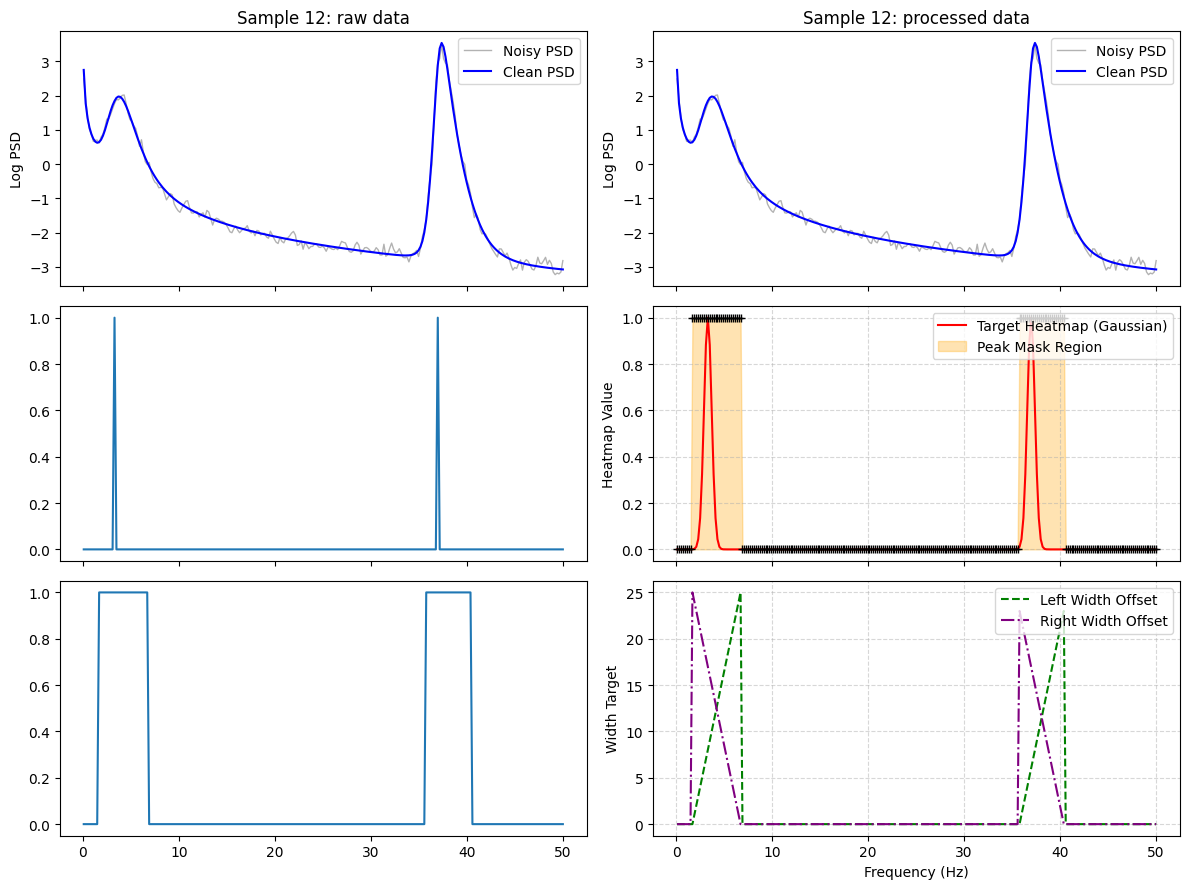

In [ ]:
# select sample index
index = 12

# need to be send back to numpy as it is in tensor
processed_sample = processed_train_ds[index]
processed_psd_noisy       = to_numpy(processed_sample["noisy_psd"])
processed_psd_clean       = to_numpy(processed_sample["clean_psd"])
processed_target_heatmap  = to_numpy(processed_sample["target_heatmap"])
processed_peak_mask       = to_numpy(processed_sample["peak_mask"])

# target_width has shape [2, n_freqs] -> left boundary offset, right boundary offset
processed_target_width     = to_numpy(processed_sample["target_width"]) # NOTE check squeeze insteqd of detqch qs it is the cqse in processing fucntion for inference
processed_left_width       = processed_target_width[0]
processed_right_width      = processed_target_width[1]

# 2. Setup Subplots
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)

# -------------------------------------------------------------------
# Plot 1: Noisy vs Clean PSD Signal
# -------------------------------------------------------------------
axes[0, 0].plot(f, raw_train_psd_noisy[index], label="Noisy PSD", color="gray", alpha=0.6, linewidth=1)
axes[0, 0].plot(f, raw_train_psd_clean[index], label="Clean PSD", color="blue", linewidth=1.5)
axes[0, 0].set_ylabel("Log PSD")
axes[0, 0].set_title(f"Sample {index}: raw data")
axes[0, 0].legend(loc="upper right")

axes[0, 1].plot(f, processed_psd_noisy, label="Noisy PSD", color="gray", alpha=0.6, linewidth=1)
axes[0, 1].plot(f, processed_psd_clean, label="Clean PSD", color="blue", linewidth=1.5)
axes[0, 1].set_ylabel("Log PSD")
axes[0, 1].set_title(f"Sample {index}: processed data")
axes[0, 1].legend(loc="upper right")

# -------------------------------------------------------------------
# Plot 2: Target Heatmap & Detected Peak Positions
# -------------------------------------------------------------------
axes[1, 0].plot(f, raw_train_mask[index][0])

axes[1, 1].plot(f, processed_target_heatmap, label="Target Heatmap (Gaussian)", color="red")
axes[1, 1].plot(f, processed_peak_mask, '+', color="black")
axes[1, 1].fill_between(f, 0, processed_peak_mask, color="orange", alpha=0.3, label="Peak Mask Region")
axes[1, 1].set_ylabel("Heatmap Value")
axes[1, 1].set_ylim(-0.05, 1.05)
axes[1, 1].legend(loc="upper right")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

# -------------------------------------------------------------------
# Plot 3: Target Width (Boundaries / Offsets)
# -------------------------------------------------------------------
axes[2, 0].plot(f, raw_train_mask[index][1])

axes[2, 1].plot(f, processed_left_width, label="Left Width Offset", color="green", linestyle="--")
axes[2, 1].plot(f, processed_right_width, label="Right Width Offset", color="purple", linestyle="-.")
axes[2, 1].set_xlabel("Frequency (Hz)")
axes[2, 1].set_ylabel("Width Target")
axes[2, 1].legend(loc="upper right")
axes[2, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


Visualize forgiveness of using heatmap for peak position

--- FOCAL LOSS RESULTS FOR SAMPLE 12 ---
1. Perfect Prediction Loss : 51.539734
2. Slightly Shifted Loss   : 0.967395
3. Missed Peak Loss        : 9.977351


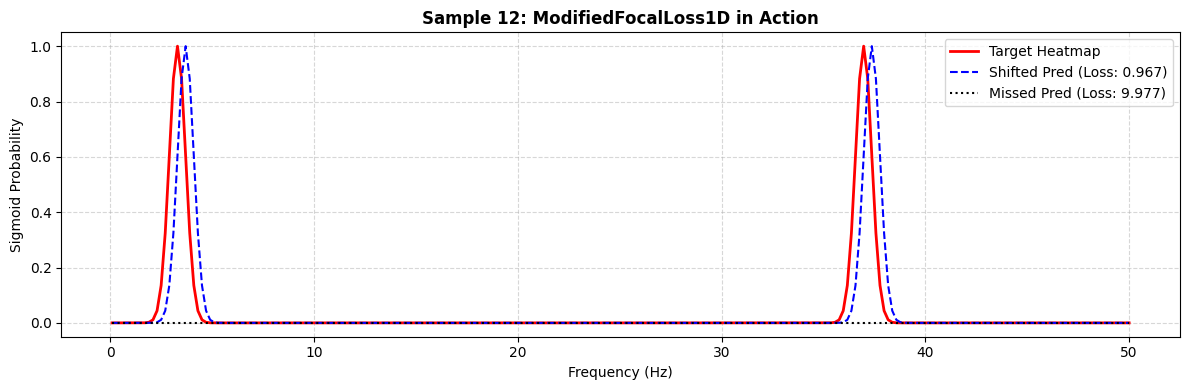

In [ ]:
# Instantiate the Focal Loss
focal_loss_fn = ModifiedFocalLoss1D(alpha=2.0, beta=4.0)

# 1. Prepare Target Heatmap Tensor: Shape [1, 1, n_freqs]
# (Requires batch and channel dimensions for PyTorch)
target_tensor = torch.tensor(
    processed_target_heatmap, dtype=torch.float32
).unsqueeze(0).unsqueeze(0)

# -------------------------------------------------------------------
# SIMULATING MODEL PREDICTIONS (Simulated Logits)
# -------------------------------------------------------------------

# Scenario A: Perfect Prediction (Matches ground truth target exactly)
# Inverse sigmoid (logit) mapping: 1.0 -> +10, 0.0 -> -10
logits_perfect = torch.where(target_tensor > 0.01, 10.0, -10.0)

# Scenario B: Slightly Shifted Peak (Offset by 2 frequency bins)
# Predicts near the peak, but slightly blurred or shifted
# shifted_target = torch.roll(target_tensor, shifts=2, dims=-1)
# logits_shifted = torch.where(shifted_target > 0.01, 5.0, -5.0)

# 1. Clamp target to safe bounds to avoid log(0)
clamped_target = torch.clamp(target_tensor, 1e-6, 1.0 - 1e-6)

# 2. Convert Gaussian heatmap to exact logits via Inverse Sigmoid (logit function)
gaussian_logits = torch.log(clamped_target / (1.0 - clamped_target))

# 3. Shift the Gaussian logits by 2 frequency bins
logits_shifted = torch.roll(gaussian_logits, shifts=2, dims=-1)

# Scenario C: Completely Missed Peak (Predicts 0 everywhere)
logits_missed = torch.full_like(target_tensor, -10.0)

# -------------------------------------------------------------------
# COMPUTE LOSSES
# -------------------------------------------------------------------
loss_perfect = focal_loss_fn(logits_perfect, target_tensor).item()
loss_shifted = focal_loss_fn(logits_shifted, target_tensor).item()
loss_missed = focal_loss_fn(logits_missed, target_tensor).item()

print(f"--- FOCAL LOSS RESULTS FOR SAMPLE {index} ---")
print(f"1. Perfect Prediction Loss : {loss_perfect:.6f}")
print(f"2. Slightly Shifted Loss   : {loss_shifted:.6f}")
print(f"3. Missed Peak Loss        : {loss_missed:.6f}")

# -------------------------------------------------------------------
# VISUALIZE PROBABILITIES VS GROUND TRUTH
# -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(f, processed_target_heatmap, "r-", label="Target Heatmap", linewidth=2)
ax.plot(
    f,
    torch.sigmoid(logits_shifted).squeeze().numpy(),
    "b--",
    label=f"Shifted Pred (Loss: {loss_shifted:.3f})",
)
ax.plot(
    f,
    torch.sigmoid(logits_missed).squeeze().numpy(),
    "k:",
    label=f"Missed Pred (Loss: {loss_missed:.3f})",
)

ax.set_title(
    f"Sample {index}: ModifiedFocalLoss1D in Action",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Sigmoid Probability")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Launch training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU Model: Tesla T4



Training Baseline_UNet on cuda
Loading split 'train' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 20000 samples.
Loading split 'val' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 2500 samples.
Loading split 'test' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 2500 samples.
[Baseline_UNet] Epoch [01/100] | Train: 4.09259 | Val: 0.76343
[Baseline_UNet] Epoch [05/100] | Train: 0.57028 | Val: 0.44408
[Baseline_UNet] Epoch [10/100] | Train: 0.50049 | Val: 0.43990
[Baseline_UNet] Epoch [15/100] | Train: 0.45495 | Val: 0.42197
[Baseline_UNet] Epoch [20/100] | Train: 0.38201 | Val: 0.45715
[Baseline_UNet] Epoch [25/100] | Train: 0.32148 | Val: 0.54584
Early stopping triggered at epoch 27.
Finished Baseline_UNet! Best Val Loss: 0.42197

      RUNNING EVALUATION ON KEYPOINT TEST SET      
 * Test Composite Loss       : 0.435202
 * Reconstruction Curve MAE  : 0.0684
 * Mean Interval Width MAE   : 1.9923 frequ

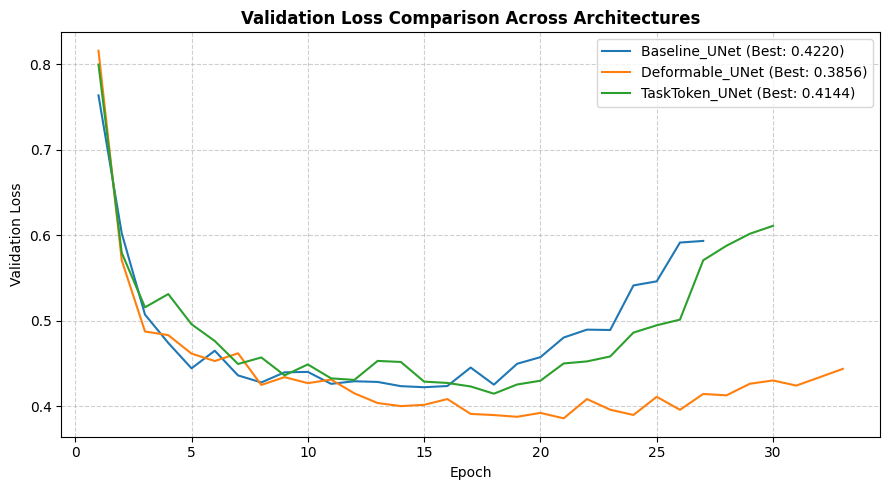

In [ ]:
dataset_path = "/content/psd_dataset_masks.npz"

models_to_train = {
    "Baseline_UNet": ResMultiTaskUNet1D(in_channels=1, base_filters=32),
    "Deformable_UNet": DeformResMultiTaskUNet1D(in_channels=1, base_filters=32),
    "TaskToken_UNet": TokenResMultiTaskUNet1D(in_channels=1, base_filters=32)
}

results = {}

for name, model_instance in models_to_train.items():
    torch.manual_seed(42)  # Maintain identical initialization consistency
    trained_mod, test_mets, hist = train_model(
        model=model_instance,
        model_name=name,
        dataset_path=dataset_path,
        max_epochs=100,
        batch_size=32,
        lr=1e-3,
        patience=12
    )
    results[name] = {
        "model": trained_mod,
        "metrics": test_mets,
        "history": hist
    }

# =====================================================================
# SUMMARY METRICS TABLE
# =====================================================================
print("\n" + "=" * 65)
print(f"{'Model Name':<20} | {'Test Loss':<12} | {'PSD MAE':<12} | {'Width MAE (bins)':<15}")
print("=" * 65)
for name, data in results.items():
    m = data["metrics"]
    print(f"{name:<20} | {m['test_loss']:<12.5f} | {m['recon_mae']:<12.4f} | {m['width_mae']:<15.4f}")
print("=" * 65)

# =====================================================================
# VALIDATION LOSS COMPARISON PLOT
# =====================================================================
plt.figure(figsize=(9, 5))
for name, data in results.items():
    hist = data["history"]
    plt.plot(hist["epoch"], hist["val_loss"], label=f"{name} (Best: {min(hist['val_loss']):.4f})")

plt.title("Validation Loss Comparison Across Architectures", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## Inference visualization

Loading split 'test' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 2500 samples.


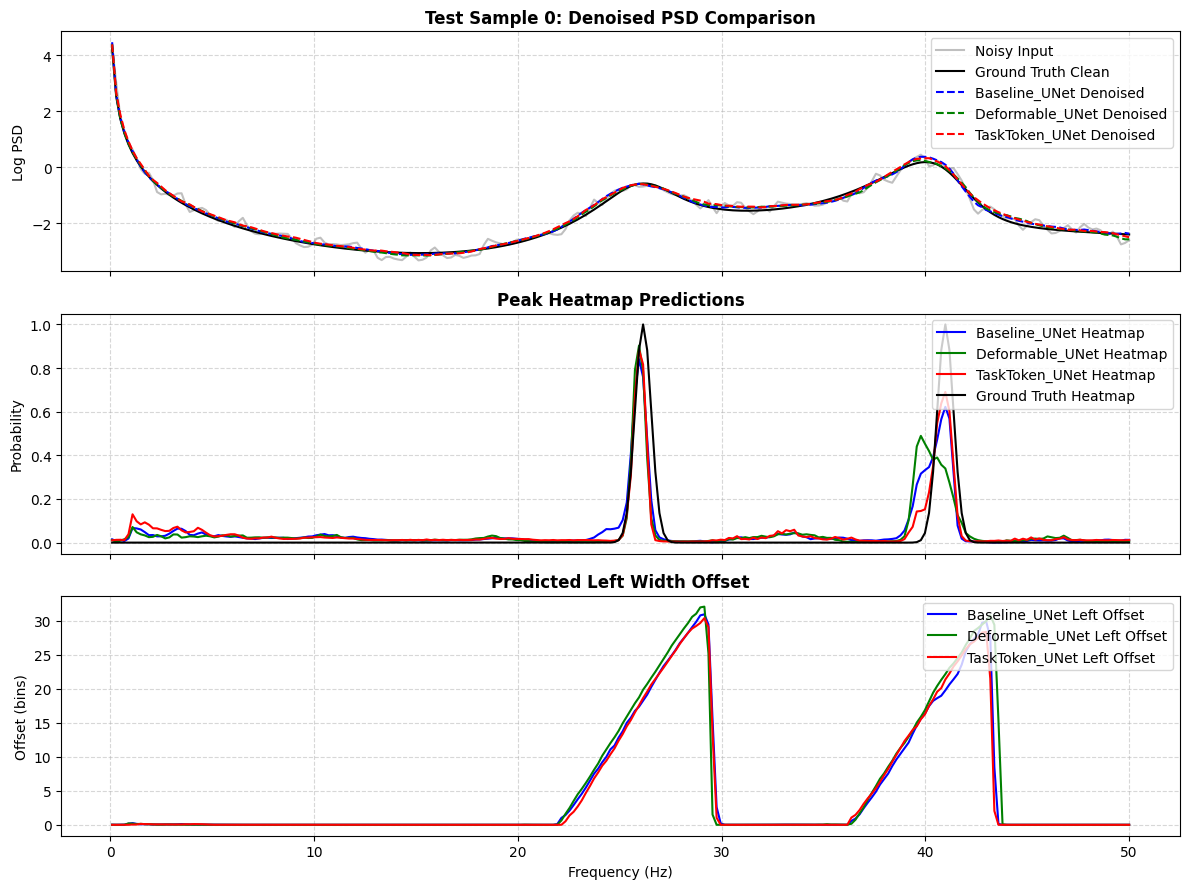

In [ ]:
test_ds = ConvertedKeypointPSDDataset(filepath=dataset_path, split="test")
sample_idx = 0
sample = test_ds[sample_idx]

f_axis = test_ds.f
noisy_in = sample["noisy_psd"].unsqueeze(0).to(device) # (1, 1, n_freqs)
clean_gt = sample["clean_psd"].squeeze().cpu().numpy()
heat_gt = sample["target_heatmap"].squeeze().cpu().numpy()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# 1. Denoised Reconstruction
axes[0].plot(f_axis, sample["noisy_psd"].squeeze().cpu().numpy(), color="gray", alpha=0.5, label="Noisy Input")
axes[0].plot(f_axis, clean_gt, color="black", linewidth=1.5, label="Ground Truth Clean")

colors = {"Baseline_UNet": "blue", "Deformable_UNet": "green", "TaskToken_UNet": "red"}

for name, data in results.items():
    model = data["model"].eval()
    with torch.no_grad():
        p_clean, p_heat, p_widths = model(noisy_in)

    # Plot Denoised Curves
    axes[0].plot(f_axis, p_clean.squeeze().cpu().numpy(), linestyle="--", color=colors[name], label=f"{name} Denoised")

    # Plot Heatmaps
    axes[1].plot(f_axis, torch.sigmoid(p_heat).squeeze().cpu().numpy(), color=colors[name], label=f"{name} Heatmap")

axes[0].set_title(f"Test Sample {sample_idx}: Denoised PSD Comparison", fontweight="bold")
axes[0].set_ylabel("Log PSD")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(f_axis, heat_gt, color="black", linewidth=1.5, label="Ground Truth Heatmap")
axes[1].set_title("Peak Heatmap Predictions", fontweight="bold")
axes[1].set_ylabel("Probability")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot Left Width Regressions
for name, data in results.items():
    model = data["model"]
    with torch.no_grad():
        _, _, p_widths = model(noisy_in)
    axes[2].plot(f_axis, p_widths.squeeze()[0].cpu().numpy(), color=colors[name], label=f"{name} Left Offset")

axes[2].set_title("Predicted Left Width Offset", fontweight="bold")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_ylabel("Offset (bins)")
axes[2].legend(loc="upper right")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
def get_OU_signal_exact(T, dt, lbda, omega, sigma):
    """
    Generates a 2D Ornstein-Uhlenbeck signal using the exact discrete-time step
    (matrix exponential solution) with zero numerical damping.
    """
    N = int(T / dt)
    t = np.linspace(0, T, N)

    x = np.zeros(N)
    y = np.zeros(N)

    # 1. Exact transition matrix M = exp(A * dt)
    decay = np.exp(-lbda * dt)
    cos_w = np.cos(omega * dt)
    sin_w = np.sin(omega * dt)

    M = decay * np.array([
        [ cos_w,  sin_w],
        [-sin_w,  cos_w]
    ])

    # 2. Exact standard deviation for discrete noise step
    sigma_eta = sigma * np.sqrt((1.0 - np.exp(-2.0 * lbda * dt)) / lbda)

    # 3. Simulate exact step
    for i in range(1, N):
        # Generate independent Gaussian noise
        eta_x = np.random.normal(0, sigma_eta)
        eta_y = np.random.normal(0, sigma_eta)

        # Matrix multiplication for deterministic state transition
        prev_state = np.array([x[i-1], y[i-1]])
        next_state = M @ prev_state + np.array([eta_x, eta_y])

        x[i] = next_state[0]
        y[i] = next_state[1]

    return t, x

def get_mixed_OU_signals_exact(T, dt, lbda_list, omega_list, sigma_list, factor_list):
    """
    Generates mixed OU signals using the exact solver.
    """
    N = int(T / dt)
    t = np.linspace(0, T, N)
    mixed_OU = np.zeros(N)

    for i in range(len(lbda_list)):
        _, x = get_OU_signal_exact(T, dt, lbda_list[i], omega_list[i], sigma_list[i])
        mixed_OU += x * factor_list[i]

    return t, mixed_OU

Evaluation

In [ ]:
# =====================================================================
# COMPREHENSIVE BENCHMARK EVALUATOR
# =====================================================================
def decode_peaks_1d_subbin(heatmap_prob, f_grid, center_thresh=0.35, kernel_size=5):
    """
    Sub-bin parabolic peak decoder for 1D heatmaps.
    """
    pad = (kernel_size - 1) // 2
    hmax = F.max_pool1d(heatmap_prob, kernel_size=kernel_size, stride=1, padding=pad)
    keep = (heatmap_prob == hmax) & (heatmap_prob >= center_thresh)

    peak_indices = torch.nonzero(keep.squeeze()).squeeze(-1)
    if peak_indices.numel() == 0:
        return np.array([], dtype=np.float64)
    if peak_indices.ndim == 0:
        peak_indices = peak_indices.unsqueeze(0)

    indices = peak_indices.detach().cpu().numpy()
    prob_1d = heatmap_prob.squeeze().detach().cpu().numpy()
    n_bins = len(f_grid)

    refined_peaks = []
    for idx in indices:
        if 0 < idx < n_bins - 1:
            y_left = prob_1d[idx - 1]
            y_center = prob_1d[idx]
            y_right = prob_1d[idx + 1]
            denom = 2.0 * (y_left - 2.0 * y_center + y_right)
            delta = np.clip((y_left - y_right) / denom, -0.5, 0.5) if abs(denom) > 1e-6 else 0.0
            df = 0.5 * (f_grid[idx + 1] - f_grid[idx - 1])
            refined_peaks.append(f_grid[idx] + delta * df)
        else:
            refined_peaks.append(f_grid[idx])

    return np.array(refined_peaks, dtype=np.float64)


def benchmark_model(model, test_loader, f_grid, criterion, device, peak_tol_hz=1.0, center_thresh=0.35):
    """
    Evaluates curve fidelity, peak detection precision/recall/F1, and boundary MAE.
    """
    model.eval()
    total_samples = 0
    test_loss_sum = 0.0

    psd_maes = []
    psd_mses = []
    width_maes = []

    total_tp = 0
    total_fp = 0
    total_fn = 0
    freq_errors = []

    with torch.no_grad():
        for batch in test_loader:
            noisy = batch['noisy_psd'].to(device)
            clean = batch['clean_psd'].to(device)
            target_heat = batch['target_heatmap'].to(device)
            target_width = batch['target_width'].to(device)
            peak_mask = batch['peak_mask'].to(device)
            batch_gpu = {k: v.to(device) for k, v in batch.items()}

            B = noisy.size(0)
            total_samples += B

            # Forward pass
            pred_psd, pred_logits, pred_widths = model(noisy)
            loss, _ = criterion(pred_psd, pred_logits, pred_widths, batch_gpu)
            test_loss_sum += loss.item() * B

            # 1. Reconstruction metrics
            abs_err = torch.abs(pred_psd - clean)
            sq_err = (pred_psd - clean) ** 2
            psd_maes.extend(abs_err.mean(dim=-1).squeeze().cpu().tolist())
            psd_mses.extend(sq_err.mean(dim=-1).squeeze().cpu().tolist())

            # 2. Width MAE inside peak regions
            mask_exp = peak_mask.repeat(1, 2, 1)
            for b in range(B):
                m_b = mask_exp[b]
                num_pts = m_b.sum().item()
                if num_pts > 0:
                    w_err = (torch.abs(pred_widths[b] - target_width[b]) * m_b).sum().item() / num_pts
                    width_maes.append(w_err)

            # 3. Peak detection metrics (Hungarian/Greedy proximity matching)
            pred_probs = torch.sigmoid(pred_logits)
            for b in range(B):
                pred_peaks_f = decode_peaks_1d_subbin(pred_probs[b:b+1], f_grid, center_thresh=center_thresh)

                # Ground truth peak indices (where target heatmap == 1.0)
                gt_indices = torch.nonzero(target_heat[b].squeeze() >= 0.99).squeeze(-1).cpu().numpy()
                gt_peaks_f = f_grid[gt_indices] if len(gt_indices) > 0 else np.array([])

                matched_gt = set()
                matched_pred = set()

                for p_idx, p_f in enumerate(pred_peaks_f):
                    if len(gt_peaks_f) == 0:
                        break
                    dists = np.abs(gt_peaks_f - p_f)
                    min_idx = np.argmin(dists)
                    if dists[min_idx] <= peak_tol_hz and min_idx not in matched_gt:
                        matched_gt.add(min_idx)
                        matched_pred.add(p_idx)
                        freq_errors.append(dists[min_idx])

                tp = len(matched_gt)
                fp = len(pred_peaks_f) - len(matched_pred)
                fn = len(gt_peaks_f) - len(matched_gt)

                total_tp += tp
                total_fp += fp
                total_fn += fn

    precision = total_tp / (total_tp + total_fp + 1e-8)
    recall = total_tp / (total_tp + total_fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    mean_mae = np.mean(psd_maes)
    mean_mse = np.mean(psd_mses)
    psnr = 10 * np.log10(1.0 / (mean_mse + 1e-8)) # Assuming normalised amplitude range ~ 1
    mean_w_err = np.mean(width_maes) if len(width_maes) > 0 else 0.0
    mean_f_err = np.mean(freq_errors) if len(freq_errors) > 0 else 0.0

    return {
        "test_loss": test_loss_sum / total_samples,
        "psd_mae": mean_mae,
        "psnr_db": psnr,
        "peak_precision": precision,
        "peak_recall": recall,
        "peak_f1": f1,
        "freq_error_hz": mean_f_err,
        "width_mae_bins": mean_w_err
    }

In [ ]:
# Ensure test loader and criterion are available
test_ds = ConvertedKeypointPSDDataset(filepath=dataset_path, split="test")
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)
criterion = MultiTaskSmoothPSDLoss(w_psd=1.0, w_heatmap=1.0, w_width=0.1)

benchmark_results = {}
for name, res in results.items():
    print(f"Evaluating {name}...")
    model = res["model"].to(device)
    metrics = benchmark_model(
        model=model,
        test_loader=test_loader,
        f_grid=test_ds.f,
        criterion=criterion,
        device=device,
        peak_tol_hz=1.0,       # Distance threshold to consider a detected peak a True Positive
        center_thresh=0.35
    )
    benchmark_results[name] = metrics

# =====================================================================
# FORMATTED COMPARISON TABLE
# =====================================================================
headers = [
    "Model Name",
    "Test Loss",
    "PSD MAE",
    "PSNR (dB)",
    "Precision",
    "Recall",
    "F1-Score",
    "Δf Err (Hz)",
    "Width MAE"
]

print("\n" + "=" * 105)
print(f"{headers[0]:<18} | {headers[1]:<9} | {headers[2]:<8} | {headers[3]:<9} | {headers[4]:<9} | {headers[5]:<8} | {headers[6]:<8} | {headers[7]:<11} | {headers[8]:<9}")
print("=" * 105)

for name, m in benchmark_results.items():
    print(
        f"{name:<18} | "
        f"{m['test_loss']:<9.4f} | "
        f"{m['psd_mae']:<8.4f} | "
        f"{m['psnr_db']:<9.2f} | "
        f"{m['peak_precision']:<9.3f} | "
        f"{m['peak_recall']:<8.3f} | "
        f"{m['peak_f1']:<8.3f} | "
        f"{m['freq_error_hz']:<11.4f} | "
        f"{m['width_mae_bins']:<9.3f}"
    )
print("=" * 105)

Loading split 'test' from /content/psd_dataset_masks.npz...
 -> Successfully loaded & converted 2500 samples.
Evaluating Baseline_UNet...
Evaluating Deformable_UNet...
Evaluating TaskToken_UNet...

Model Name         | Test Loss | PSD MAE  | PSNR (dB) | Precision | Recall   | F1-Score | Δf Err (Hz) | Width MAE
Baseline_UNet      | 0.4352    | 0.0685   | 20.34     | 0.983     | 0.951    | 0.967    | 0.1506      | 1.867    
Deformable_UNet    | 0.3981    | 0.0653   | 20.65     | 0.986     | 0.950    | 0.968    | 0.1414      | 1.541    
TaskToken_UNet     | 0.4220    | 0.0681   | 20.53     | 0.983     | 0.951    | 0.967    | 0.1456      | 1.821    


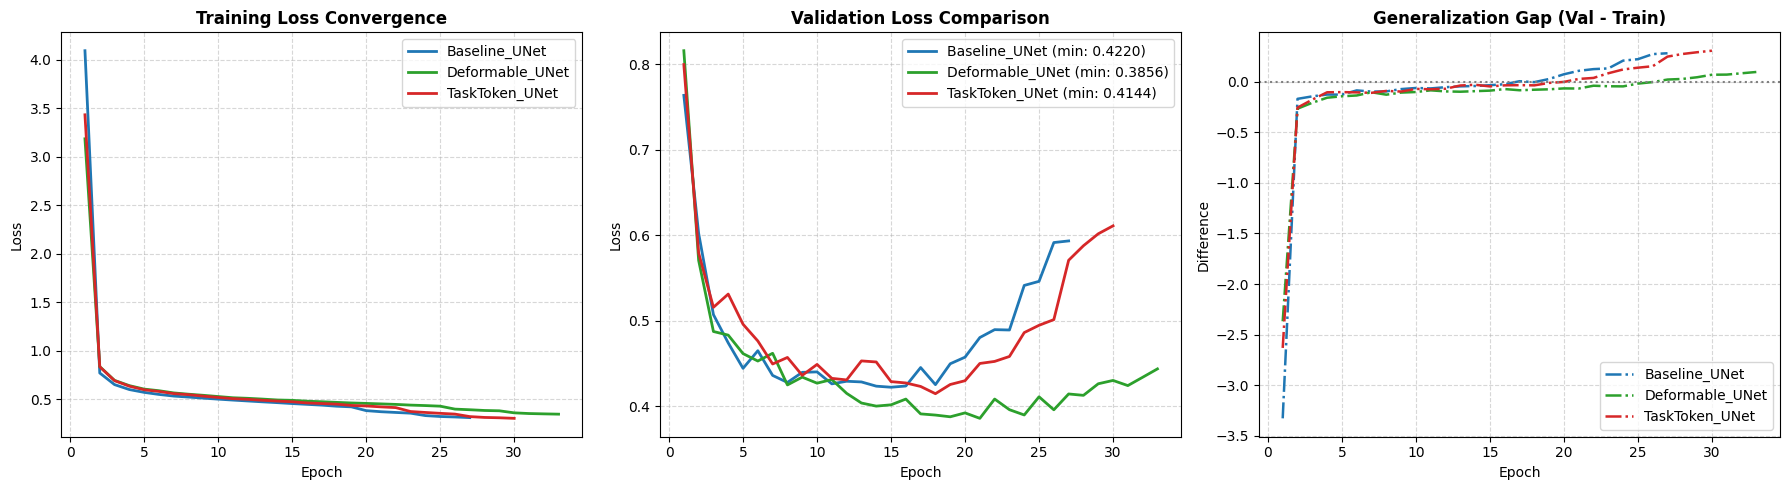

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = {"Baseline_UNet": "#1f77b4", "Deformable_UNet": "#2ca02c", "TaskToken_UNet": "#d62728"}

# 1. Training Loss
for name, res in results.items():
    hist = res["history"]
    axes[0].plot(hist["epoch"], hist["train_loss"], label=name, color=palette.get(name, "black"), lw=2)
axes[0].set_title("Training Loss Convergence", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Validation Loss
for name, res in results.items():
    hist = res["history"]
    best_v = min(hist["val_loss"])
    axes[1].plot(hist["epoch"], hist["val_loss"], label=f"{name} (min: {best_v:.4f})", color=palette.get(name, "black"), lw=2)
axes[1].set_title("Validation Loss Comparison", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Generalization Gap (Overfitting Diagnosis)
for name, res in results.items():
    hist = res["history"]
    gap = np.array(hist["val_loss"]) - np.array(hist["train_loss"])
    axes[2].plot(hist["epoch"], gap, label=name, color=palette.get(name, "black"), lw=1.8, linestyle="-.")
axes[2].set_title("Generalization Gap (Val - Train)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Difference")
axes[2].axhline(0, color="gray", linestyle=":")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

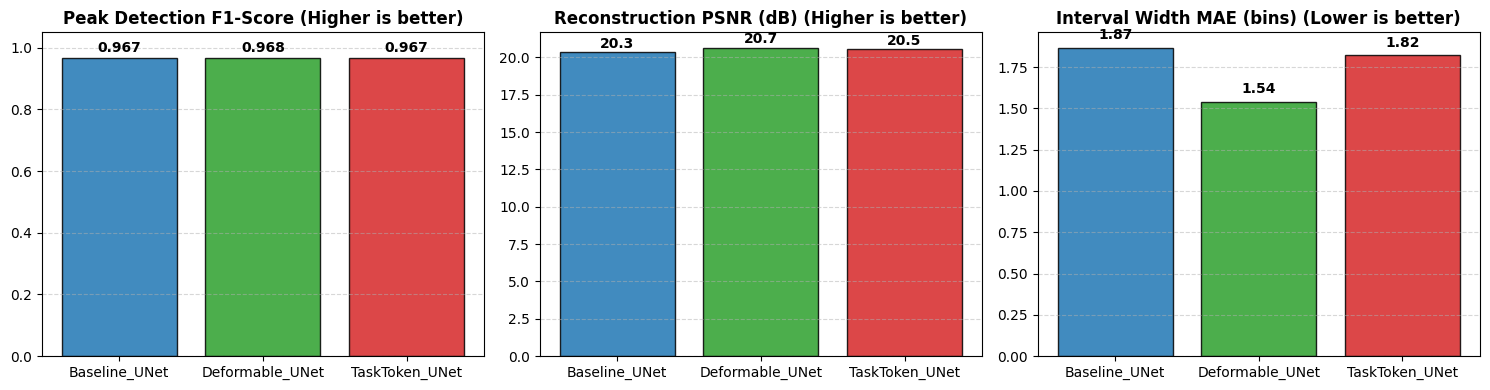

In [ ]:
model_names = list(benchmark_results.keys())
f1_scores = [benchmark_results[m]["peak_f1"] for m in model_names]
psnr_vals = [benchmark_results[m]["psnr_db"] for m in model_names]
width_errs = [benchmark_results[m]["width_mae_bins"] for m in model_names]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bar_colors = [palette.get(m, "gray") for m in model_names]

# F1-Score
axes[0].bar(model_names, f1_scores, color=bar_colors, alpha=0.85, edgecolor="black")
axes[0].set_title("Peak Detection F1-Score (Higher is better)", fontweight="bold")
axes[0].set_ylim(0, 1.05)
for i, v in enumerate(f1_scores):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# PSNR
axes[1].bar(model_names, psnr_vals, color=bar_colors, alpha=0.85, edgecolor="black")
axes[1].set_title("Reconstruction PSNR (dB) (Higher is better)", fontweight="bold")
for i, v in enumerate(psnr_vals):
    axes[1].text(i, v + 0.3, f"{v:.1f}", ha="center", fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Width Error
axes[2].bar(model_names, width_errs, color=bar_colors, alpha=0.85, edgecolor="black")
axes[2].set_title("Interval Width MAE (bins) (Lower is better)", fontweight="bold")
for i, v in enumerate(width_errs):
    axes[2].text(i, v + 0.05, f"{v:.2f}", ha="center", fontweight="bold")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()